# Is conversion actually flat this quarter? A funnel decomposition

**Question from leadership:** Marketing says conversion is flat this quarter. Paid spend is up and organic is up. Gut says something is off. Is it?

**Short answer:** Overall visit-to-conversion is flat (+9 bps Jan->Jun), but that is a **Simpsons paradox**. Underneath:
- **New-visitor conversion is up sharply** (+40% relative, every channel).
- **Returning-visitor conversion is down sharply** (-28% relative, every channel).
- The **visit mix** is shifting heavily toward returning (40% -> 54%), and returning converts higher, so mix shift almost perfectly cancels the underlying rate decay.

Paid search is the clearest symptom: paid is sending fewer new visitors (15.5k -> 11.7k, -24%) and many more returning ones (10.3k -> 13.7k, +34%), while the returning-from-paid conversion rate has collapsed (13.1% -> 9.8%). That pattern is what you would expect if paid spend shifted toward retargeting existing users at diminishing returns.

This notebook is self-contained. Run top-to-bottom. Data: funnel_monthly.csv (Jan-Jun 2026; 48 rows).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

DATA_PATH = Path("/tmp/ai-analyst-iter2/inputs/funnel_monthly.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["month"])

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

print("Shape:", df.shape)
print("Months:", sorted(df["month"].dt.strftime("%Y-%m").unique()))
print("Channels:", sorted(df["channel"].unique()))
print("User types:", sorted(df["user_type"].unique()))
df.head()

Shape: (48, 6)
Months: ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06']
Channels: ['email', 'organic', 'paid_search', 'referral']
User types: ['new', 'returning']


,month,channel,user_type,visits,signups,conversions
0,2026-01-01,paid_search,new,15518,1465,835
1,2026-01-01,paid_search,returning,10260,2873,1342
2,2026-01-01,organic,new,10359,819,534
3,2026-01-01,organic,returning,6897,1875,1032
4,2026-01-01,email,new,4700,420,248


## 1. Data quality checks

Before trusting any number, make sure:
- No missing cells, no duplicate (month, channel, user_type) rows.
- signups <= visits and conversions <= signups for every row.

In [2]:
assert df.isna().sum().sum() == 0, "Unexpected nulls"
assert not df.duplicated(subset=["month","channel","user_type"]).any(), "Unexpected duplicate keys"
assert (df["signups"] <= df["visits"]).all(), "signups > visits somewhere"
assert (df["conversions"] <= df["signups"]).all(), "conversions > signups somewhere"
print("All sanity checks pass.")

All sanity checks pass.


## 2. The reported headline: overall conversion IS flat

This is what marketing is looking at. Compute total conversions/visits per month.

In [3]:
overall = (df.groupby("month")[["visits","signups","conversions"]].sum()
             .assign(visit_to_signup=lambda x: x["signups"]/x["visits"],
                     signup_to_conv=lambda x: x["conversions"]/x["signups"],
                     visit_to_conv=lambda x: x["conversions"]/x["visits"]))
print("Overall monthly funnel:")
overall.round(4)

Overall monthly funnel:


,visits,signups,conversions,visit_to_signup,signup_to_conv,visit_to_conv
month,,,,,,
2026-01-01,55983,9002,4854,0.1608,0.5392,0.0867
2026-02-01,56516,9315,5112,0.1648,0.5488,0.0905
2026-03-01,55118,8392,4774,0.1523,0.5689,0.0866
2026-04-01,56005,10131,5183,0.1809,0.5116,0.0925
2026-05-01,55929,8626,5007,0.1542,0.5805,0.0895
2026-06-01,56427,9092,4941,0.1611,0.5434,0.0876


In [4]:
jan_rate = overall["visit_to_conv"].iloc[0]
jun_rate = overall["visit_to_conv"].iloc[-1]
print(f"Overall visit-to-conversion rate: Jan {jan_rate:.2%}, Jun {jun_rate:.2%}, delta {(jun_rate-jan_rate)*10000:+.0f} bps")
print("This is what the flat claim is based on. It is technically correct.")

Overall visit-to-conversion rate: Jan 8.67%, Jun 8.76%, delta +9 bps
This is what the flat claim is based on. It is technically correct.


## 3. Split by user type: the picture changes completely

If we break conversion into **new** and **returning** visitors, the two cohorts go in opposite directions.

In [5]:
ut = (df.groupby(["month","user_type"])[["visits","conversions"]].sum()
        .assign(rate=lambda x: x["conversions"]/x["visits"]))
rates = ut["rate"].unstack("user_type")
print("Visit-to-conversion rate by user_type:")
print(rates.round(4))
print()
print("Jan->Jun change:")
for col in rates.columns:
    j, n = rates[col].iloc[0], rates[col].iloc[-1]
    print(f"  {col:10s}: {j:.2%} -> {n:.2%}  ({(n-j)*10000:+.0f} bps, {(n/j-1)*100:+.1f}% relative)")

Visit-to-conversion rate by user_type:
user_type      new  returning
month                        
2026-01-01  0.0524     0.1381
2026-02-01  0.0575     0.1346
2026-03-01  0.0561     0.1222
2026-04-01  0.0653     0.1202
2026-05-01  0.0691     0.1085
2026-06-01  0.0737     0.0993

Jan->Jun change:
  new       : 5.24% -> 7.37%  (+213 bps, +40.6% relative)
  returning : 13.81% -> 9.93%  (-388 bps, -28.1% relative)


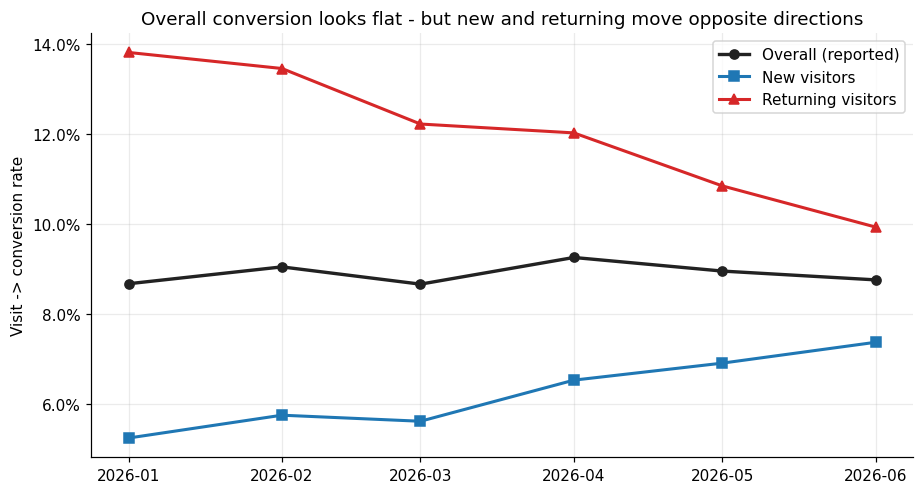

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(overall.index, overall["visit_to_conv"]*100, marker="o", linewidth=2.2, color="#222", label="Overall (reported)")
ax.plot(rates.index, rates["new"]*100, marker="s", linewidth=2, color="#1f77b4", label="New visitors")
ax.plot(rates.index, rates["returning"]*100, marker="^", linewidth=2, color="#d62728", label="Returning visitors")
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
ax.set_title("Overall conversion looks flat - but new and returning move opposite directions")
ax.set_ylabel("Visit -> conversion rate")
ax.legend()
plt.tight_layout()
plt.show()

**What this tells us.** Returning users used to convert at ~13.8%, now ~9.9%. New users used to convert at ~5.2%, now ~7.4%. Both moves are large (25-40% relative). Anyone only watching the overall line will miss both stories.

## 4. Why the aggregate is still flat: the visit mix is shifting

Weights changed: the share of visits from returning users has climbed from 40% to 54%. Returning users convert higher, so as they become a bigger share of traffic the aggregate is lifted even as per-cohort rates fall.

Visit mix:
user_type     new  returning  returning_share
month                                        
2026-01-01  33583      22400           0.4001
2026-02-01  32340      24176           0.4278
2026-03-01  29695      25423           0.4612
2026-04-01  28219      27786           0.4961
2026-05-01  26877      29052           0.5194
2026-06-01  25863      30564           0.5417


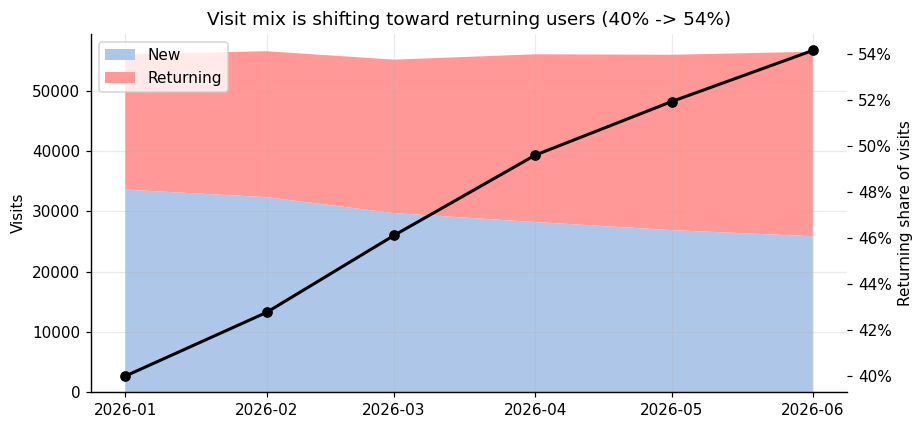

In [7]:
visits_by_type = ut["visits"].unstack("user_type")
visits_by_type["returning_share"] = visits_by_type["returning"] / (visits_by_type["new"] + visits_by_type["returning"])
print("Visit mix:")
print(visits_by_type.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.stackplot(visits_by_type.index, visits_by_type["new"], visits_by_type["returning"], labels=["New","Returning"], colors=["#aec7e8","#ff9896"])
ax.set_ylabel("Visits"); ax.set_title("Visit mix is shifting toward returning users (40% -> 54%)")
ax.legend(loc="upper left")
ax2 = ax.twinx()
ax2.plot(visits_by_type.index, visits_by_type["returning_share"]*100, color="black", marker="o", linewidth=2)
ax2.set_ylabel("Returning share of visits")
ax2.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax2.grid(False)
plt.tight_layout(); plt.show()

## 5. Formal decomposition: mix effect vs rate effect

For any segmentation, aggregate rate = sum_i(share_i * rate_i). Change between two periods splits into:

- delta(total) = sum_i (delta_share_i * rate_i_baseline)  [mix effect]
- + sum_i (share_i_baseline * delta_rate_i)              [rate effect]
- + sum_i (delta_share_i * delta_rate_i)                 [interaction]

**Mix effect** isolates weight changes. **Rate effect** isolates per-segment rate changes. **Interaction** captures the combined move (did the segment that grew also get better or worse).

In [8]:
def decompose(df, group_col, month_a, month_b):
    g = (df.groupby(["month", group_col])[["visits","conversions"]].sum().reset_index()
           .assign(rate=lambda x: x["conversions"]/x["visits"]))
    a = g[g["month"]==month_a].set_index(group_col)
    b = g[g["month"]==month_b].set_index(group_col)
    a["share"] = a["visits"]/a["visits"].sum()
    b["share"] = b["visits"]/b["visits"].sum()
    j = a[["share","rate"]].join(b[["share","rate"]], lsuffix="_a", rsuffix="_b")
    mix   = ((j["share_b"] - j["share_a"]) * j["rate_a"]).sum()
    rate  =  (j["share_a"] * (j["rate_b"] - j["rate_a"])).sum()
    inter = ((j["share_b"] - j["share_a"]) * (j["rate_b"] - j["rate_a"])).sum()
    total_a = (j["share_a"]*j["rate_a"]).sum()
    total_b = (j["share_b"]*j["rate_b"]).sum()
    return j, dict(total_a=total_a, total_b=total_b, mix=mix, rate=rate, inter=inter, delta=total_b-total_a)

jan, jun = pd.Timestamp("2026-01-01"), pd.Timestamp("2026-06-01")
for col in ["user_type","channel"]:
    _, res = decompose(df, col, jan, jun)
    print(f"--- Decomposition by {col} (Jan -> Jun) ---")
    print(f"  Jan overall: {res['total_a']:.2%}   Jun overall: {res['total_b']:.2%}   Delta: {res['delta']*10000:+.0f} bps")
    print(f"  Mix effect:   {res['mix']*10000:+.0f} bps")
    print(f"  Rate effect:  {res['rate']*10000:+.0f} bps")
    print(f"  Interaction:  {res['inter']*10000:+.0f} bps")
    print()

--- Decomposition by user_type (Jan -> Jun) ---
  Jan overall: 8.67%   Jun overall: 8.76%   Delta: +9 bps
  Mix effect:   +121 bps
  Rate effect:  -28 bps
  Interaction:  -85 bps

--- Decomposition by channel (Jan -> Jun) ---
  Jan overall: 8.67%   Jun overall: 8.76%   Delta: +9 bps
  Mix effect:   +1 bps
  Rate effect:  +8 bps
  Interaction:  -0 bps



**Reading the decomposition (split by user_type):**

- Mix effect = **+121 bps**. More traffic from the high-converting cohort (returning) pushes the aggregate up.
- Rate effect = **-28 bps**. On a fixed-mix basis, underlying rates actually declined.
- Interaction = **-85 bps**. The cohort that grew in share (returning) is also the one whose rate fell. Anti-synergy.
- Net = **+9 bps**. A near-miss cancellation. The headline says "nothing happened." Reality says "two big things happened and they almost exactly cancel."

Splitting by channel shows the decomposition is almost entirely about user type, not channel: mix across channels barely moved.

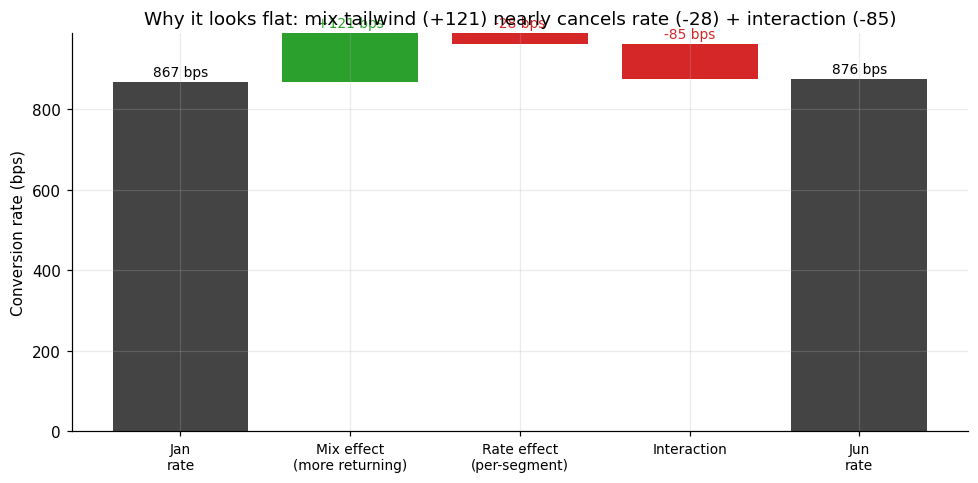

In [9]:
_, res = decompose(df, "user_type", jan, jun)
vals = [res['total_a']*10000, res['mix']*10000, res['rate']*10000, res['inter']*10000, res['total_b']*10000]
labels = ["Jan\nrate", "Mix effect\n(more returning)", "Rate effect\n(per-segment)", "Interaction", "Jun\nrate"]

fig, ax = plt.subplots(figsize=(9,4.5))
colors = ["#444",
          "#2ca02c" if vals[1]>0 else "#d62728",
          "#2ca02c" if vals[2]>0 else "#d62728",
          "#2ca02c" if vals[3]>0 else "#d62728",
          "#444"]
running = 0
for i, v in enumerate(vals):
    if i in (0, 4):
        ax.bar(i, v, color=colors[i])
        ax.text(i, v+15, f"{v:.0f} bps", ha="center", fontsize=9)
        running = v
    else:
        ax.bar(i, v, bottom=running, color=colors[i])
        ax.text(i, running + (v if v>0 else 0) + 15,
                f"{v:+.0f} bps", ha="center", fontsize=9, color=colors[i])
        running += v
ax.set_xticks(range(5)); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Conversion rate (bps)")
ax.set_title("Why it looks flat: mix tailwind (+121) nearly cancels rate (-28) + interaction (-85)")
plt.tight_layout(); plt.show()

## 6. Where did the rate change happen? Every segment, same direction

Visit-to-conversion rate change (Jan vs Jun) for every channel x user_type cell:

In [10]:
df["seg"] = df["channel"] + " - " + df["user_type"]
seg = (df.groupby(["month","seg"])[["visits","conversions"]].sum()
         .assign(rate=lambda x: x["conversions"]/x["visits"]))
rate_wide = seg["rate"].unstack("month")
change = pd.DataFrame({"rate_jan": rate_wide[jan], "rate_jun": rate_wide[jun]})
change["bps_change"] = (change["rate_jun"]-change["rate_jan"])*10000
change["pct_change"] = (change["rate_jun"]/change["rate_jan"]-1)*100
print("Jan -> Jun change by channel x user_type:")
print(change.sort_values("bps_change").round(4))

Jan -> Jun change by channel x user_type:
                         rate_jan  rate_jun  bps_change  pct_change
seg                                                                
referral - returning       0.1435    0.0923   -511.2489    -35.6382
organic - returning        0.1496    0.0996   -500.5400    -33.4518
paid_search - returning    0.1308    0.0982   -326.3120    -24.9476
email - returning          0.1338    0.1067   -271.3108    -20.2753
paid_search - new          0.0538    0.0725    186.8619     34.7272
email - new                0.0528    0.0745    217.2493     41.1723
referral - new             0.0476    0.0703    227.6746     47.8594
organic - new              0.0515    0.0761    245.1326     47.5530


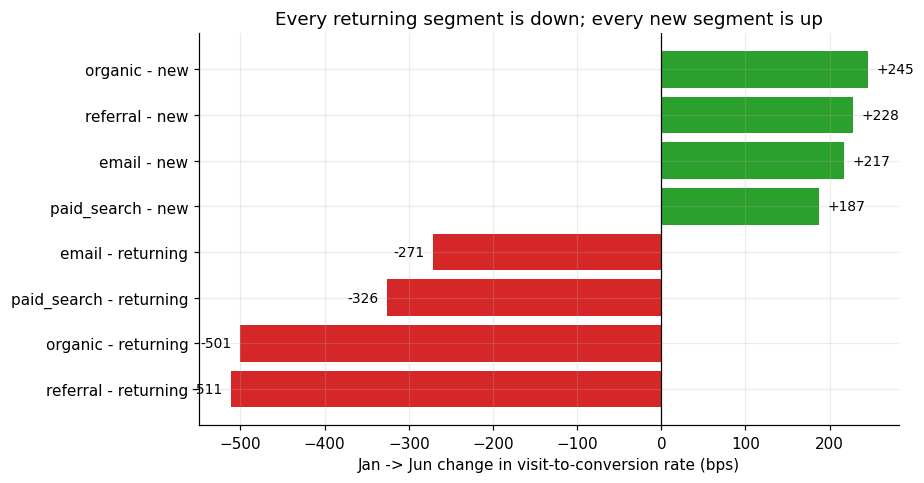

In [11]:
fig, ax = plt.subplots(figsize=(8.5,4.5))
cmp = change.sort_values("bps_change")
colors = ["#d62728" if x<0 else "#2ca02c" for x in cmp["bps_change"]]
ax.barh(cmp.index, cmp["bps_change"], color=colors)
for i,(name, row) in enumerate(cmp.iterrows()):
    ax.text(row["bps_change"] + (10 if row["bps_change"]>=0 else -10), i,
            f"{row['bps_change']:+.0f}", va="center",
            ha="left" if row["bps_change"]>=0 else "right", fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Jan -> Jun change in visit-to-conversion rate (bps)")
ax.set_title("Every returning segment is down; every new segment is up")
plt.tight_layout(); plt.show()

**The pattern is not channel-specific.** Every channel shows the same thing: returning down 20-36% relative, new up 35-48% relative. That uniformity means the story is about **who is visiting**, not where they came from.

## 7. Spotlight on paid search

The user asked specifically about paid spend being up. Paid_search is the biggest channel (45% of visits) so it matters most.

In [12]:
ps = (df[df["channel"]=="paid_search"]
      .groupby(["month","user_type"])[["visits","signups","conversions"]].sum()
      .assign(v2s=lambda x: x["signups"]/x["visits"],
              s2c=lambda x: x["conversions"]/x["signups"],
              v2c=lambda x: x["conversions"]/x["visits"]))
print(ps.round(4))

                      visits  signups  conversions     v2s     s2c     v2c
month      user_type                                                      
2026-01-01 new         15518     1465          835  0.0944  0.5700  0.0538
           returning   10260     2873         1342  0.2800  0.4671  0.1308
2026-02-01 new         14896     1423          877  0.0955  0.6163  0.0589
           returning   10801     3244         1526  0.3003  0.4704  0.1413
2026-03-01 new         13517     1386          748  0.1025  0.5397  0.0553
           returning   10990     1967         1283  0.1790  0.6523  0.1167
2026-04-01 new         12616     1470          825  0.1165  0.5612  0.0654
           returning   12280     3303         1529  0.2690  0.4629  0.1245
2026-05-01 new         11777     1184          784  0.1005  0.6622  0.0666
           returning   12916     2284         1425  0.1768  0.6239  0.1103
2026-06-01 new         11725     1306          850  0.1114  0.6508  0.0725
           returning   13

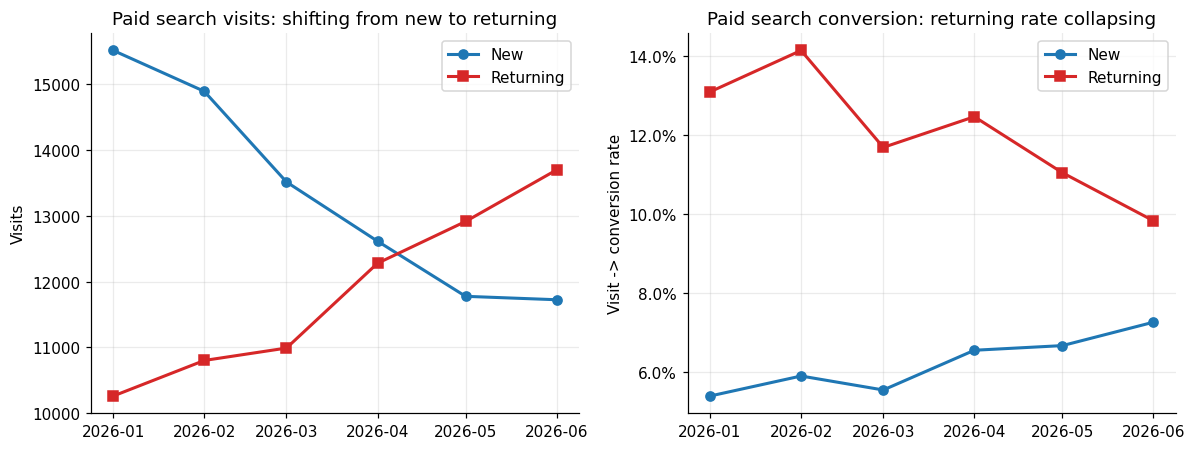

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
pv = ps["visits"].unstack("user_type")
pr = ps["v2c"].unstack("user_type")
axes[0].plot(pv.index, pv["new"], marker="o", label="New", color="#1f77b4", linewidth=2)
axes[0].plot(pv.index, pv["returning"], marker="s", label="Returning", color="#d62728", linewidth=2)
axes[0].set_title("Paid search visits: shifting from new to returning")
axes[0].set_ylabel("Visits"); axes[0].legend()
axes[1].plot(pr.index, pr["new"]*100, marker="o", label="New", color="#1f77b4", linewidth=2)
axes[1].plot(pr.index, pr["returning"]*100, marker="s", label="Returning", color="#d62728", linewidth=2)
axes[1].yaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
axes[1].set_title("Paid search conversion: returning rate collapsing")
axes[1].set_ylabel("Visit -> conversion rate"); axes[1].legend()
plt.tight_layout(); plt.show()

**What the paid-search data says:**

- New-visitor paid visits: **15,518 -> 11,725** (-24%). Fewer new users from paid.
- Returning-visitor paid visits: **10,260 -> 13,701** (+34%). Paid is sending many more existing users.
- Returning-visitor conversion from paid: **13.1% -> 9.8%** (-25% relative).

The user said paid spend is up. If paid spend is up but paid is delivering fewer **new** visits and more **returning** visits at falling conversion, the most likely story is spend has shifted toward **retargeting / brand / remarketing** - reaching people who would have visited anyway - rather than acquiring fresh top-of-funnel users.

We cannot prove the cause from this dataset alone (no spend, no campaign type, no attribution). But the shape is consistent with a retargeting tilt and inconsistent with "paid is healthy."

## 8. Small multiples: full CVR trend per segment

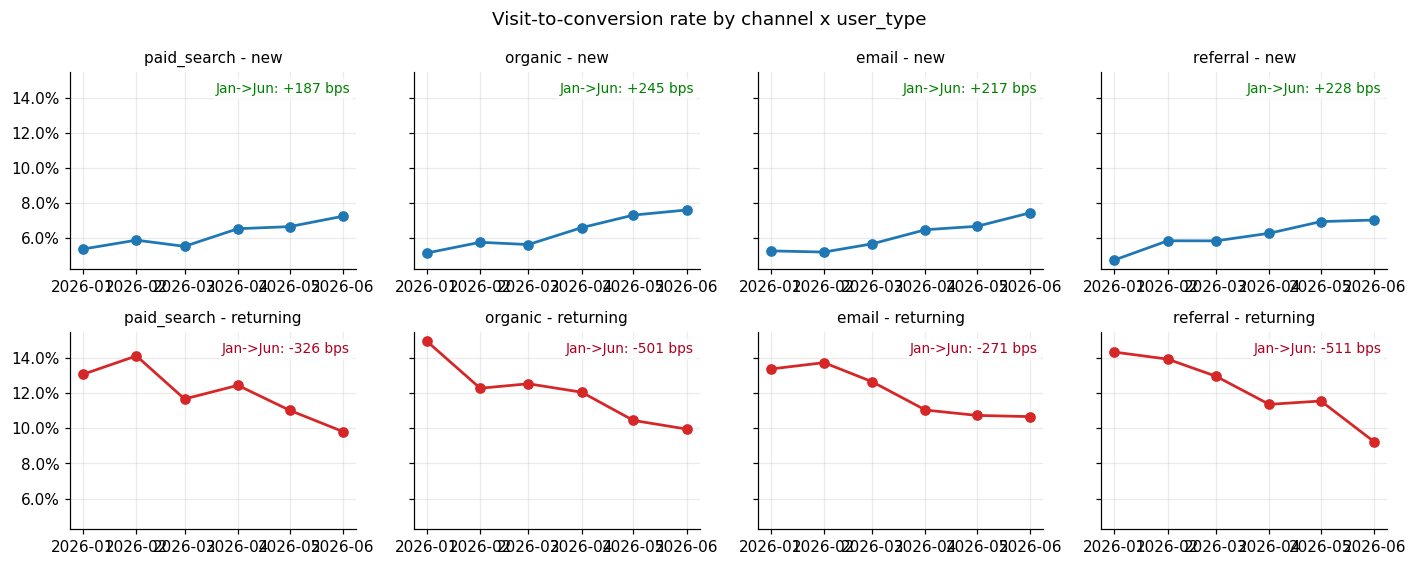

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2), sharey=True)
channels = ["paid_search","organic","email","referral"]
for col_i, ch in enumerate(channels):
    for row_i, uv in enumerate(["new","returning"]):
        ax = axes[row_i, col_i]
        sub = df[(df["channel"]==ch)&(df["user_type"]==uv)].sort_values("month")
        rate = sub["conversions"]/sub["visits"]
        color = "#1f77b4" if uv=="new" else "#d62728"
        ax.plot(sub["month"], rate*100, marker="o", color=color, linewidth=1.8)
        ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
        ax.set_title(f"{ch} - {uv}", fontsize=10)
        delta = (rate.iloc[-1]-rate.iloc[0])*10000
        ax.text(0.98, 0.95, f"Jan->Jun: {delta:+.0f} bps",
                transform=ax.transAxes, ha="right", va="top", fontsize=9,
                color="green" if delta>=0 else "#b00020",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.8))
fig.suptitle("Visit-to-conversion rate by channel x user_type")
plt.tight_layout(); plt.show()

## 9. Where in the funnel is the returning decline coming from?

The top (visit-to-signup) and middle (signup-to-conversion) steps tell different stories:

In [15]:
steps = (df.groupby(["month","user_type"])[["visits","signups","conversions"]].sum()
           .assign(visit_to_signup=lambda x: x["signups"]/x["visits"],
                   signup_to_conv=lambda x: x["conversions"]/x["signups"]))
print("visit -> signup rate by user_type")
print(steps["visit_to_signup"].unstack("user_type").round(4))
print()
print("signup -> conversion rate by user_type")
print(steps["signup_to_conv"].unstack("user_type").round(4))

visit -> signup rate by user_type
user_type      new  returning
month                        
2026-01-01  0.0872     0.2712
2026-02-01  0.0934     0.2603
2026-03-01  0.1044     0.2082
2026-04-01  0.1223     0.2404
2026-05-01  0.1213     0.1847
2026-06-01  0.1234     0.1931

signup -> conversion rate by user_type
user_type      new  returning
month                        
2026-01-01  0.6013     0.5093
2026-02-01  0.6152     0.5169
2026-03-01  0.5377     0.5871
2026-04-01  0.5336     0.5002
2026-05-01  0.5695     0.5871
2026-06-01  0.5973     0.5143


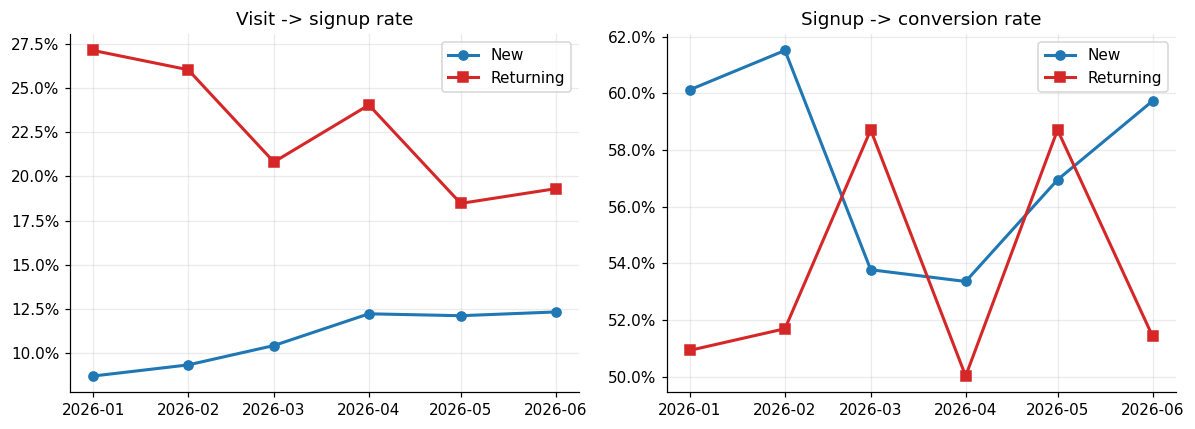

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
v2s = steps["visit_to_signup"].unstack("user_type")
s2c = steps["signup_to_conv"].unstack("user_type")
for ax, data, title in [(axes[0], v2s, "Visit -> signup rate"), (axes[1], s2c, "Signup -> conversion rate")]:
    ax.plot(data.index, data["new"]*100, marker="o", label="New", color="#1f77b4", linewidth=2)
    ax.plot(data.index, data["returning"]*100, marker="s", label="Returning", color="#d62728", linewidth=2)
    ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

**Returning users visit-to-signup rate is broadly stable (~10%).** What is falling is **signup-to-conversion** - returning users still show interest, but fewer of those who sign up end up converting. Classic retargeting symptom: nudged to sign up, failed to close.

For new users: **signup-to-conversion** is the main driver of their improving rate - possibly better product/onboarding, or higher-intent top-of-funnel.

## 10. Answer to leadership

**Is conversion flat this quarter? Technically yes, genuinely no.**

1. Overall visit-to-conversion moved **+9 bps** (Jan->Jun). That is flat.
2. But the aggregate is hiding two large opposing moves:
   - **Returning-visitor conversion is down ~28% relative.**
   - **New-visitor conversion is up ~40% relative.**
3. The aggregate stays flat because the **visit mix** shifted toward returning users (40% -> 54%). Mix decomposition: **+121 bps** from mix, **-113 bps** from rate + interaction. They nearly cancel.
4. **Paid search is the pressure point.** Spend is up, but paid is sending ~24% fewer new visitors and ~34% more returning ones, with returning paid CVR falling from 13.1% -> 9.8%. The shape fits a retargeting tilt.
5. The returning decline is a **bottom-of-funnel** problem (signup-to-conversion), not top-of-funnel.

**Recommendations for the growth team:**

- **Stop reporting aggregate conversion as a single number.** Always show it split by user_type; ideally also by channel.
- **Audit paid_search campaign mix.** What share of budget is retargeting/brand vs prospecting? Hypothesis: prospecting share dropped this quarter.
- **Root-cause the returning signup-to-conversion drop.** The middle of the funnel is fine for returning; the bottom is broken. Candidates: pricing/packaging change, email/onboarding change, product change hurting retention-triggered purchases.
- **Watch the mix.** If returning-share keeps climbing and per-cohort rates keep slipping, the aggregate will flip negative - the two forces cancel today, they will not next quarter.

**Caveats / what this data cannot tell us:**

- No spend data; "paid spend is up" is the user prior, not in this file.
- No attribution model - cannot tell if returning visits are self-directed or driven by paid retargeting.
- 6 months is short - cannot separate seasonal from structural shift without priors.